# Rayleigh商はなぜPCAから量子力学まで現れるのか

## 概要

PCAは射影後の分散を最大化し、量子力学の変分法はエネルギーの期待値を最小化する。どちらも、二次形式をベクトルの長さの二乗で割るRayleigh商に帰着する。本記事では固有値との関係を導き、二次元のデータと二準位系をPythonで計算する。

## 実行環境

仮想環境とカーネルの表示名は `wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SciPy、Matplotlibを使う。セルは上から実行する。SVGの保存先はノートブックと同じ階層の `105_nb_files` である。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import numpy as np
import scipy
from scipy.linalg import eigh
from scipy.optimize import minimize_scalar
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import Math, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix  # 仮想環境での実行を確認する。
print('実行環境: wa-src(3.14.6)')
print(f'Python: {platform.python_version()} / OS: {platform.system()}')
print(f'NumPy: {np.__version__} / SciPy: {scipy.__version__}')
print(f'Matplotlib: {matplotlib.__version__}')

# Notebookのフォルダーとリポジトリ直下のどちらからでも実行できる。
work_dir = Path.cwd()
relative_dir = Path('rec/Interdisciplinarity/105')
notebook_dir = work_dir / relative_dir if (work_dir / relative_dir).is_dir() else work_dir
image_dir = notebook_dir / '105_nb_files'
image_dir.mkdir(exist_ok=True)

# 小数は有効数字3桁で表示する。計算自体は丸めない。
def sig3(value):
    return f'{float(value):#.3g}'


np.set_printoptions(formatter={'float_kind': sig3})
# 再実行前にも図を表示できるよう、NotebookにはPNGの表示用データも添える。
set_matplotlib_formats('svg', 'png')
plt.rcParams.update({
    'figure.figsize': (7, 4),
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'rayleigh-105',
})


def save_plot(fig, filename):
    # 軸とカラーバーも同じ桁数にそろえ、SVGを保存する。
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
    fig.tight_layout()
    fig.savefig(image_dir / filename, format='svg', metadata={'Date': None})
    plt.show()
    plt.close(fig)

実行環境: wa-src(3.14.6)
Python: 3.14.6 / OS: Darwin
NumPy: 2.5.4 / SciPy: 1.18.1
Matplotlib: 3.11.2


## 1. 長さに依存しない二次形式

実対称行列 $\mathbf{A}$ と非零ベクトル $\mathbf{x}$ に対し、Rayleigh商を定義する。

<div>

$$
R_{\mathbf{A}}(\mathbf{x})=
\frac{\mathbf{x}^{T}\mathbf{A}\mathbf{x}}{\mathbf{x}^{T}\mathbf{x}}.
$$

</div>

実数 $a\ne0$ を掛けても、分子と分母の倍率が消える。

$$
R_{\mathbf{A}}(a\mathbf{x})
=\frac{a^2\mathbf{x}^{T}\mathbf{A}\mathbf{x}}{a^2\mathbf{x}^{T}\mathbf{x}}
=R_{\mathbf{A}}(\mathbf{x}).
$$

したがって、長さを1に固定して方向だけを調べればよい。

### 固有値が上下限になる理由

正規直交固有ベクトルを $\mathbf{u}_i$、固有値を $\lambda_i$ とし、$\mathbf{x}=\sum_i c_i\mathbf{u}_i$ と展開する。直交性 $\mathbf{u}_i^T\mathbf{u}_j=\delta_{ij}$ を使うと、

$$
\begin{aligned}
\mathbf{x}^{T}\mathbf{A}\mathbf{x}
&=\sum_{i,j}c_i c_j\lambda_j\mathbf{u}_i^T\mathbf{u}_j
=\sum_i\lambda_i c_i^2,\\
\mathbf{x}^{T}\mathbf{x}&=\sum_{i,j}c_i c_j\delta_{ij}=\sum_i c_i^2,\\
R_{\mathbf{A}}(\mathbf{x})&=\sum_i p_i\lambda_i,
\qquad p_i=\frac{c_i^2}{\sum_j c_j^2},\quad \sum_i p_i=1.
\end{aligned}
$$

$p_i\ge0$ なので、Rayleigh商は固有値の加重平均である。

<div>

$$
\lambda_{\min}\le R_{\mathbf{A}}(\mathbf{x})\le\lambda_{\max}.
$$

</div>

両端の値は対応する固有空間の非零ベクトルで達成される。[固有値の変分的な説明](https://www.cs.cornell.edu/courses/cs6210/2025fa/lec/2025-11-03.html)と同じ結果である。

停留条件も計算する。$f=\mathbf{x}^T\mathbf{A}\mathbf{x}$、$g=\mathbf{x}^T\mathbf{x}$ と置くと、

$$
\begin{aligned}
\nabla f&=(\mathbf{A}+\mathbf{A}^T)\mathbf{x}=2\mathbf{A}\mathbf{x},
\quad \nabla g=2\mathbf{x},\\
\nabla R&=\frac{g\nabla f-f\nabla g}{g^2}
=\frac{2}{g}(\mathbf{A}\mathbf{x}-R\mathbf{x}),\\
\nabla R=\mathbf{0}&\ \Longleftrightarrow\ \mathbf{A}\mathbf{x}=R\mathbf{x}.
\end{aligned}
$$

停留点は固有ベクトルになる。中間の固有値に対応する停留点まで極値になるとは限らない。

### 二次元の例

$$
\mathbf{A}=\begin{pmatrix}4&1\\1&2\end{pmatrix},\qquad
\mathbf{x}(\theta)=\begin{pmatrix}\cos\theta\\\sin\theta\end{pmatrix}.
$$

$$
\begin{aligned}
R(\theta)&=4\cos^2\theta+2\sin\theta\cos\theta+2\sin^2\theta\\
&=3+\cos2\theta+\sin2\theta,\\
\det(\mathbf{A}-\lambda\mathbf{I})&=(4-\lambda)(2-\lambda)-1
=\lambda^2-6\lambda+7=0,\\
\lambda&=3\pm\sqrt{2}.
\end{aligned}
$$

図1は方向とRayleigh商の関係である。図2では原点を除き、同じ方向の色が同じになる。私はこの図があると、正規化の役割を確認しやすいと感じる。

{'A': array([[4.00, 1.00],
       [1.00, 2.00]]),
 'eigenvalues': array([1.59, 4.41])}


<IPython.core.display.Math object>

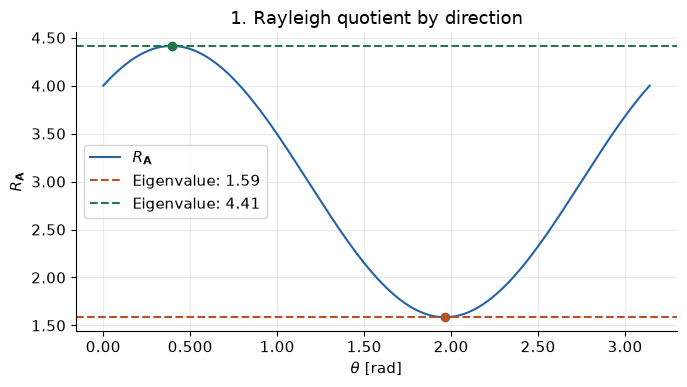

In [2]:
def rayleigh(matrix, vector):
    # vdotは第1引数を複素共役にする。matrixは実対称またはHermitianとする。
    norm_squared = np.vdot(vector, vector).real
    if norm_squared == 0:
        raise ValueError('零ベクトルのRayleigh商は定義されない。')
    return float((np.vdot(vector, matrix @ vector) / norm_squared).real)


A = np.array([[4, 1], [1, 2]], dtype=float)
eigenvalues, eigenvectors = eigh(A)  # 固有値は昇順で返る。
pprint({'A': A, 'eigenvalues': eigenvalues})
display(Math(r'\lambda_{\min}=3-\sqrt{2}\approx' + sig3(eigenvalues[0])
             + r',\qquad\lambda_{\max}=3+\sqrt{2}\approx' + sig3(eigenvalues[1])))

angles = np.linspace(0, np.pi, 501)
directions = np.column_stack((np.cos(angles), np.sin(angles)))
quotients = np.array([rayleigh(A, vector) for vector in directions])
fig, ax = plt.subplots()
ax.plot(angles, quotients, color='#2563a6', label=r'$R_{\mathbf{A}}$')
for index, color in [(0, '#b45426'), (1, '#26764b')]:
    direction = eigenvectors[:, index]
    angle = np.arctan2(direction[1], direction[0]) % np.pi
    value = eigenvalues[index]
    ax.axhline(value, color=color, linestyle='--', label=f'Eigenvalue: {sig3(value)}')
    ax.scatter(angle, value, color=color, zorder=3)
ax.set(xlabel=r'$\theta$ [rad]', ylabel=r'$R_{\mathbf{A}}$', title='1. Rayleigh quotient by direction')
ax.legend()
ax.grid(alpha=0.250)
save_plot(fig, '01_rayleigh_angle.svg')

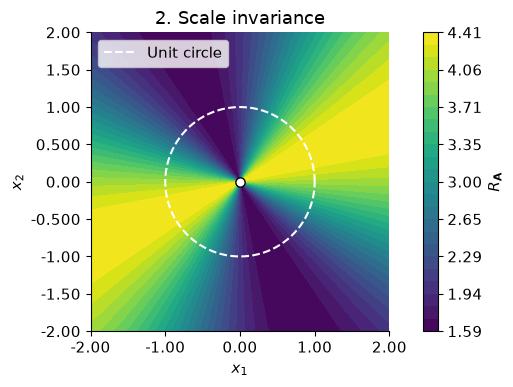

In [3]:
# 原点には値を割り当てず、穴として表示する。
grid = np.linspace(-2, 2, 241)
xx, yy = np.meshgrid(grid, grid)
norm_squared = xx**2 + yy**2
field = np.full_like(xx, np.nan)
np.divide(4 * xx**2 + 2 * xx * yy + 2 * yy**2, norm_squared,
          out=field, where=norm_squared > 0)

fig, ax = plt.subplots()
contour = ax.contourf(xx, yy, field, levels=np.linspace(*eigenvalues, 25), cmap='viridis')
circle = np.linspace(0, 2 * np.pi, 301)
ax.plot(np.cos(circle), np.sin(circle), color='white', linestyle='--', label='Unit circle')
ax.scatter(0, 0, facecolor='white', edgecolor='black', s=45, zorder=3)
ax.set(xlabel=r'$x_1$', ylabel=r'$x_2$', title='2. Scale invariance', aspect='equal')
fig.colorbar(contour, ax=ax, label=r'$R_{\mathbf{A}}$')
ax.legend(loc='upper left')
save_plot(fig, '02_rayleigh_plane.svg')

## 2. PCAは分散を最大化する

$n$ 個の観測を行に並べ、列ごとの平均を引いた行列を $\mathbf{X}$ とする。ここでは標準化は行わない。単位ベクトル $\mathbf{w}$ への射影は $\mathbf{y}=\mathbf{X}\mathbf{w}$ であり、その平均も0である。

<div>

$$
\begin{aligned}
s_y^2&=\frac{\sum_{k=1}^n y_k^2}{n-1}
=\frac{\mathbf{y}^T\mathbf{y}}{n-1}
=\frac{\mathbf{w}^T\mathbf{X}^T\mathbf{X}\mathbf{w}}{n-1}\\
&=\mathbf{w}^T\mathbf{C}\mathbf{w}=R_{\mathbf{C}}(\mathbf{w}),
\qquad\mathbf{C}=\frac{\mathbf{X}^T\mathbf{X}}{n-1}.
\end{aligned}
$$

</div>

したがって、第1主成分の方向は共分散行列 $\mathbf{C}$ の最大固有値に対応する。残りの方向は、それまでの主成分方向に直交する条件で選ぶ。これは[PCAの分散と固有値の関係](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)である。

母共分散を先ほどの $\mathbf{A}$ とする乱数を生成する。有限標本の $\mathbf{C}$ は $\mathbf{A}$ と一致するとは限らない。図3の線の半長は各主成分の標準偏差の2倍である。図4では、射影値から直接計算した分散とRayleigh商を重ね、主成分ごとの分布も確認する。

{'PC_variances': array([4.70, 1.48]),
 'explained_variance_ratio': array([0.760, 0.240]),
 'sample_covariance': array([[4.21, 1.15],
       [1.15, 1.97]])}


<IPython.core.display.Math object>

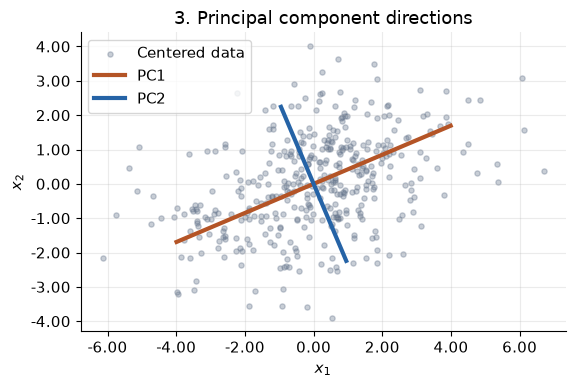

In [4]:
rng = np.random.default_rng(105)
observations = rng.multivariate_normal(mean=[0, 0], cov=A, size=400)
X = observations - observations.mean(axis=0)
C = X.T @ X / (len(X) - 1)
variances, components = eigh(C)
variances = variances[::-1]
components = components[:, ::-1]  # 第1主成分から順に並べる。
scores = X @ components
pprint({'sample_covariance': C, 'PC_variances': variances,
        'explained_variance_ratio': variances / variances.sum()})
display(Math(r's_{\mathrm{PC1}}^2=\lambda_{\max}(\mathbf{C})\approx'
             + sig3(variances[0])))

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], s=14, alpha=0.350, color='#64748b', label='Centered data')
for index, color in [(0, '#b45426'), (1, '#2563a6')]:
    extent = 2 * np.sqrt(variances[index]) * components[:, index]
    ax.plot([-extent[0], extent[0]], [-extent[1], extent[1]],
            color=color, linewidth=3, label=f'PC{index + 1}')
ax.set(xlabel=r'$x_1$', ylabel=r'$x_2$', title='3. Principal component directions', aspect='equal')
ax.legend()
ax.grid(alpha=0.250)
save_plot(fig, '03_pca_directions.svg')

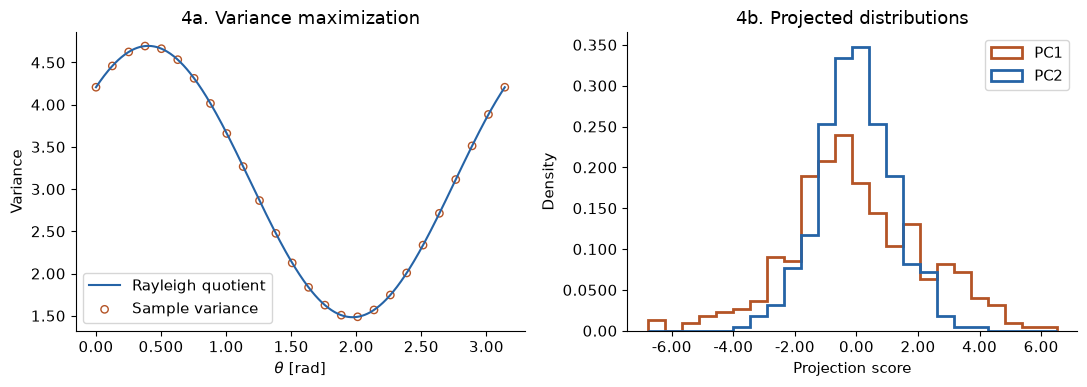

In [5]:
projected_variance = np.var(X @ directions.T, axis=0, ddof=1)
covariance_quotient = np.array([rayleigh(C, vector) for vector in directions])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(angles, covariance_quotient, label='Rayleigh quotient', color='#2563a6')
axes[0].scatter(angles[::20], projected_variance[::20], s=28,
                facecolor='none', edgecolor='#b45426', label='Sample variance')
axes[0].set(xlabel=r'$\theta$ [rad]', ylabel='Variance', title='4a. Variance maximization')
axes[0].legend()

# 同じビンを使い、主成分ごとの広がりを比較する。
bins = np.linspace(scores.min(), scores.max(), 25)
for index, color in [(0, '#b45426'), (1, '#2563a6')]:
    axes[1].hist(scores[:, index], bins=bins, density=True, histtype='step',
                 linewidth=2, color=color, label=f'PC{index + 1}')
axes[1].set(xlabel='Projection score', ylabel='Density', title='4b. Projected distributions')
axes[1].legend()
save_plot(fig, '04_pca_variance.svg')

## 3. 量子力学はエネルギーを最小化する

有限次元の量子系では、ハミルトニアンはHermitian行列 $\mathbf{H}=\mathbf{H}^{\dagger}$ で表される。$\dagger$ は共役転置である。状態ベクトル $\mathbf{z}\ne\mathbf{0}$ のエネルギー期待値もRayleigh商になる。

<div>

$$
E(\mathbf{z})=\frac{\mathbf{z}^{\dagger}\mathbf{H}\mathbf{z}}
{\mathbf{z}^{\dagger}\mathbf{z}}
=\frac{\sum_j E_j|c_j|^2}{\sum_j|c_j|^2}\ge E_0.
$$

</div>

ここで $\mathbf{z}=\sum_j c_j\mathbf{v}_j$、$\mathbf{H}\mathbf{v}_j=E_j\mathbf{v}_j$ であり、$E_0$ は最小固有値である。実数の場合の導出で $c_j^2$ を $|c_j|^2$ に置き換えればよい。試行状態を制限して最小化した期待値は、真の基底エネルギーの上界となる。これが[変分原理](https://quantummechanics.ucsd.edu/ph130a/130_notes/node375.html)である。

単位エネルギーを固定した二準位モデルを使う。

$$
\begin{aligned}
\mathbf{H}&=\begin{pmatrix}1&-1\\-1&2\end{pmatrix},\\
\det(\mathbf{H}-E\mathbf{I})&=(1-E)(2-E)-1=E^2-3E+1=0,\\
E_0&=\frac{3-\sqrt5}{2},\qquad E_1=\frac{3+\sqrt5}{2}.
\end{aligned}
$$

正規化した状態を $\mathbf{z}=(\cos\theta,e^{i\phi}\sin\theta)^T$ とする。$c=\cos\theta$、$s=\sin\theta$ と略記すると、

$$
\begin{aligned}
E(\theta,\phi)&=c(c-e^{i\phi}s)+e^{-i\phi}s(-c+2e^{i\phi}s)\\
&=c^2+2s^2-(e^{i\phi}+e^{-i\phi})cs\\
&=\cos^2\theta+2\sin^2\theta-2\cos\theta\sin\theta\cos\phi.
\end{aligned}
$$

図5では $\phi=0$ として角度を最適化する。このモデルは実数の基底状態を持つため、厳密な最小値を再現できる。図6は相対位相も変えた結果である。同じ成分の絶対値でも、相対位相によって期待値が変わる。

{'energy_eigenvalues': array([0.382, 2.62]),
 'theta_min': '0.554',
 'variational_energy': '0.382'}


<IPython.core.display.Math object>

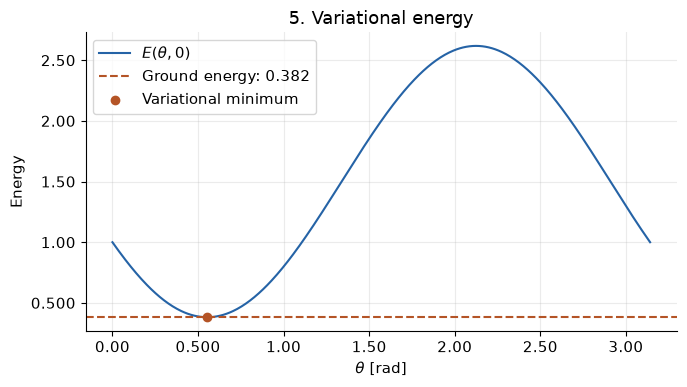

In [6]:
H = np.array([[1, -1], [-1, 2]], dtype=float)
energies, states = eigh(H)


def trial_state(theta, phase=0):
    return np.array([np.cos(theta), np.exp(1j * phase) * np.sin(theta)])


def trial_energy(theta, phase=0):
    return rayleigh(H, trial_state(theta, phase))


# このモデルの基底状態は、両成分を非負に選べる。
optimum = minimize_scalar(trial_energy, bounds=(0, np.pi / 2), method='bounded')
assert optimum.success
pprint({'energy_eigenvalues': energies,
        'theta_min': sig3(optimum.x), 'variational_energy': sig3(optimum.fun)})
display(Math(r'E_0=\frac{3-\sqrt5}{2}\approx' + sig3(energies[0])
             + r',\qquad E(\theta_*,0)\approx' + sig3(optimum.fun)))

energy_curve = np.array([trial_energy(theta) for theta in angles])
fig, ax = plt.subplots()
ax.plot(angles, energy_curve, color='#2563a6', label=r'$E(\theta,0)$')
ax.axhline(energies[0], color='#b45426', linestyle='--', label=f'Ground energy: {sig3(energies[0])}')
ax.scatter(optimum.x, optimum.fun, color='#b45426', zorder=3, label='Variational minimum')
ax.set(xlabel=r'$\theta$ [rad]', ylabel='Energy', title='5. Variational energy')
ax.legend()
ax.grid(alpha=0.250)
save_plot(fig, '05_quantum_energy.svg')

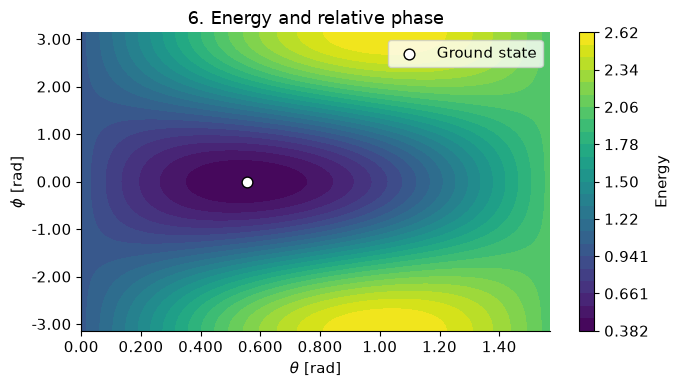

解析式・数値計算の一致を確認した。SVGファイルを6点保存した。


In [7]:
theta_grid = np.linspace(0, np.pi / 2, 181)
phase_grid = np.linspace(-np.pi, np.pi, 241)
tt, pp = np.meshgrid(theta_grid, phase_grid)
energy_map = (np.cos(tt)**2 + 2 * np.sin(tt)**2
              - 2 * np.cos(tt) * np.sin(tt) * np.cos(pp))
fig, ax = plt.subplots()
contour = ax.contourf(tt, pp, energy_map, levels=np.linspace(*energies, 25), cmap='viridis')
ax.scatter(optimum.x, 0, color='white', edgecolor='black', s=60, label='Ground state')
ax.set(xlabel=r'$\theta$ [rad]', ylabel=r'$\phi$ [rad]', title='6. Energy and relative phase')
fig.colorbar(contour, ax=ax, label='Energy')
ax.legend()
save_plot(fig, '06_quantum_phase.svg')

# 解析式、固有値計算、射影分散、変分計算の整合性を確認する。
np.testing.assert_allclose(eigenvalues, [3 - np.sqrt(2), 3 + np.sqrt(2)])
np.testing.assert_allclose(projected_variance, covariance_quotient)
np.testing.assert_allclose(np.var(scores, axis=0, ddof=1), variances)
np.testing.assert_allclose(optimum.fun, energies[0], atol=1.00e-10)
sample_theta, sample_phase = tt[::20, ::20], pp[::20, ::20]
direct_energy = np.array([
    trial_energy(theta, phase)
    for theta, phase in zip(sample_theta.ravel(), sample_phase.ravel())
]).reshape(sample_theta.shape)
np.testing.assert_allclose(direct_energy, energy_map[::20, ::20])
assert energy_map.min() >= energies[0] - 1.00e-12
assert energy_map.max() <= energies[1] + 1.00e-12
print('解析式・数値計算の一致を確認した。SVGファイルを6点保存した。')

## 結論

この記事では、PCAの分散最大化と量子力学のエネルギー最小化が、Rayleigh商の固有値による評価に帰着することを示した。

どちらも、方向や状態に対する二次形式を正規化して比較する問題である。PCAでは共分散行列の最大固有値、量子系ではハミルトニアンの最小固有値を求める。共通して現れる理由は、この数学的な構造にある。